This script is designed to make two plots, the first is a deep convective fraction plot from four different models, and the other is from observations over the same period

In [1]:
import glob
from joblib import Parallel, delayed
#from catalog_plotter import plot_var, get_array
import numpy as np
import cartopy as cp
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import plotter_config as pc
import sim_name_remap as map
import netCDF4 as nc4
import os
import datetime as dt
from scipy.interpolate import interp1d
import pickle as pkl
import matplotlib.tri as tri
from plotter import plot_map
import jdcal
import utils
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import ListedColormap, LinearSegmentedColormap

In [2]:

# This function collects the simulated cloud top fields for the desired date range
def get_simcloudalt(sim, date0, date1):

    sim_files = sorted(glob.glob(map.remap[sim]))
    
    sim_files0 = [item for item in sim_files if date0 in item][0]
    find0 = list(sim_files).index(sim_files0)
    sim_files1 = [item for item in sim_files if date1 in item][0]
    find1 = list(sim_files).index(sim_files1)
    
    sim_files = sim_files[find0:find1+1]
    #print(sim_files)
    
    # Crack open the first file and read the convective top information, then loop over the rest
    sim_nc = nc4.Dataset(sim_files[0])
    #simcloudprs = sim_nc.variables['PCONVT'][:]/100.
    simcloudalt = sim_nc.variables['CLDHGT'][:]
    simconvprec = sim_nc.variables['PRECC'][:]*1000.*3600.  # Convert to mm/hr
    simlon = sim_nc.variables['lon'][:]
    simlat = sim_nc.variables['lat'][:]
    
    for f in sim_files[1:]:
        sim_nc = nc4.Dataset(f)
        simcloudalt = np.append(simcloudalt, sim_nc.variables['CLDHGT'][:], axis=0)
        simconvprec = np.append(simconvprec, sim_nc.variables['PRECC'][:]*1000.*3600., axis=0)
    
    print('Simulated clouds shape = ', np.shape(simcloudalt))

    return simcloudalt, simconvprec, simlon, simlat


In [3]:

# Calculate convective fraction
def calc_obs_convfrac(lon, lat, cloudalt, deep_thresh):
    
    NT = np.shape(cloudalt)[0]  
    convfrac = np.zeros(np.shape(np.squeeze(cloudalt[0,:,:])))-999
    for ln in range(len(lon)):
        for lt in range(len(lat)):
            
            convfrac[lt,ln] = len(np.where(cloudalt[:,lt,ln] >= deep_thresh)[0])*100./NT

    print('Range of Deep Convective Fraction values = ', np.min(convfrac), np.max(convfrac))

    return convfrac
                        

In [4]:

# Calculate convective fraction
def calc_model_convfrac(lon, lat, simcloudalt, simconvprec, deep_thresh, prec_thresh):

    print(np.shape(simcloudalt))
    
    NT = np.shape(simcloudalt)[0]  
    convfrac = np.zeros(np.shape(np.squeeze(simcloudalt[0,:,:])))-999
    for ln in range(len(lon)):
        for lt in range(len(lat)):            
            
            convfrac[lt,ln] = len(np.where((simcloudalt[:,lt,ln] >= deep_thresh) & (simconvprec[:,lt,ln] >= prec_thresh))[0])*100./NT

    print('Range of Deep Convective Fraction values = ', np.min(convfrac), np.max(convfrac))

    return convfrac
                        

In [5]:

#sims = ['2022_ERA5_ZM','2022_MERRA2_ZM','2022_ERA5_ZMKE','2022_MERRA2_ZMKE']  # These will be used to make a 2x2 plot
#sims = ['2022_M2-weak','2022_M2-strong','2022_E5-weak','2022_E5-strong','2022_FreeRun']
sims = ['2022_M2-weak','2022_M2-strong','2022_E5-weak','2022_E5-strong','2022_FreeRun']

#date0 = '2022-08-10'
#date1 = '2022-08-20' 
#date0 = '2022-08-01'
#date1 = '2022-08-31'
#date0 = '2022-08-15'
#date1 = '2022-08-19'
date0 = '2022-05-01'   # Used to make Figure 1!
date1 = '2022-09-30'

#deep_thresh = 300.   # hPa    # Formerly 200!!!!
deep_thresh = 12.    # switching to an altitude (km)

#prec_thresh = 0.75  # mm/hr, for the ASM (see Pfister et al 2022 Table 1)
#####prec_thresh = 1.0   # mm/hr, as a general approximation for everywhere     ##### Should be this, maybe
#prec_thresh = 1.5   # mm/hr, for the tropics (see Pfister et al 2022 Table 1)
prec_thresh = 0.0

extent = [-180,180,-90,90]
#extent = [30,160,0,45]
#extent = [100,140,10,40]


In [6]:

# Retreive cloud observations and subset in time
cld_file = '/glade/work/wsmith/cloud_data_file_final.pkl'
with open(cld_file, 'rb') as f: cloud_jd, cloudlon, cloudlat, cloudalt, cloudtheta, trop_alt, trop_theta = pkl.load(f)
#obscloudprs = utils.alt2prs(cloudalt, 7.6, 1013.)


In [7]:

init_jd = sum(jdcal.gcal2jd(int(date0[0:4]), int(date0[5:7]), int(date0[8:])))  
end_jd  = sum(jdcal.gcal2jd(int(date1[0:4]), int(date1[5:7]), int(date1[8:]))) + 0.875 # To end at the end of the day
tind0 = list(cloud_jd).index(init_jd)
tind1 = list(cloud_jd).index(end_jd)

obscloudalt = cloudalt[tind0:tind1+1,:,:]

print('Observed clouds shape = ', np.shape(obscloudalt))

obsconvfrac = calc_obs_convfrac(cloudlon, cloudlat, obscloudalt, deep_thresh)


Observed clouds shape =  (1224, 400, 1440)
Range of Deep Convective Fraction values =  0.0 23.447712418300654


In [8]:

# Get the files and subset to the user-defined date range
sim0_cloudalt, sim0_convprec, simlon, simlat = get_simcloudalt(sims[0], date0, date1)
sim1_cloudalt, sim1_convprec, simlon, simlat = get_simcloudalt(sims[1], date0, date1)
sim2_cloudalt, sim2_convprec, simlon, simlat = get_simcloudalt(sims[2], date0, date1)
sim3_cloudalt, sim3_convprec, simlon, simlat = get_simcloudalt(sims[3], date0, date1)
sim4_cloudalt, sim4_convprec, simlon, simlat = get_simcloudalt(sims[4], date0, date1)


Simulated clouds shape =  (1224, 192, 288)
Simulated clouds shape =  (1224, 192, 288)
Simulated clouds shape =  (1224, 192, 288)
Simulated clouds shape =  (1224, 192, 288)
Simulated clouds shape =  (1224, 192, 288)


In [9]:

# Calculate the convective fractions for models and observations
sim0_convfrac = calc_model_convfrac(simlon, simlat, sim0_cloudalt, sim0_convprec, deep_thresh, prec_thresh)
sim1_convfrac = calc_model_convfrac(simlon, simlat, sim1_cloudalt, sim1_convprec, deep_thresh, prec_thresh)
sim2_convfrac = calc_model_convfrac(simlon, simlat, sim2_cloudalt, sim2_convprec, deep_thresh, prec_thresh)
sim3_convfrac = calc_model_convfrac(simlon, simlat, sim3_cloudalt, sim3_convprec, deep_thresh, prec_thresh)
sim4_convfrac = calc_model_convfrac(simlon, simlat, sim4_cloudalt, sim4_convprec, deep_thresh, prec_thresh)


(1224, 192, 288)
Range of Deep Convective Fraction values =  0.0 34.31372549019608
(1224, 192, 288)
Range of Deep Convective Fraction values =  0.0 44.28104575163399
(1224, 192, 288)
Range of Deep Convective Fraction values =  0.0 27.04248366013072
(1224, 192, 288)
Range of Deep Convective Fraction values =  0.0 44.36274509803921
(1224, 192, 288)
Range of Deep Convective Fraction values =  0.0 22.95751633986928


In [10]:

print(np.shape(simlon))
print(np.shape(simlat))
print(np.shape(sim0_convfrac))
    

(288,)
(192,)
(192, 288)


In [11]:
def convfrac_map_plot(ax, simlon, simlat, simconvfrac, cmap, norm, simstr, extent, let):
    
    pixplt = ax.pcolormesh(simlon, simlat, simconvfrac, cmap=cmap, norm=norm)
    ax.plot([-180,180],[20,20],linewidth=0.5,color='gray')
    ax.plot([-180,180],[-20,-20],linewidth=0.5,color='gray')
    ax.coastlines()
    ax.set_title(let + simstr)
    ax.set_extent(extent)


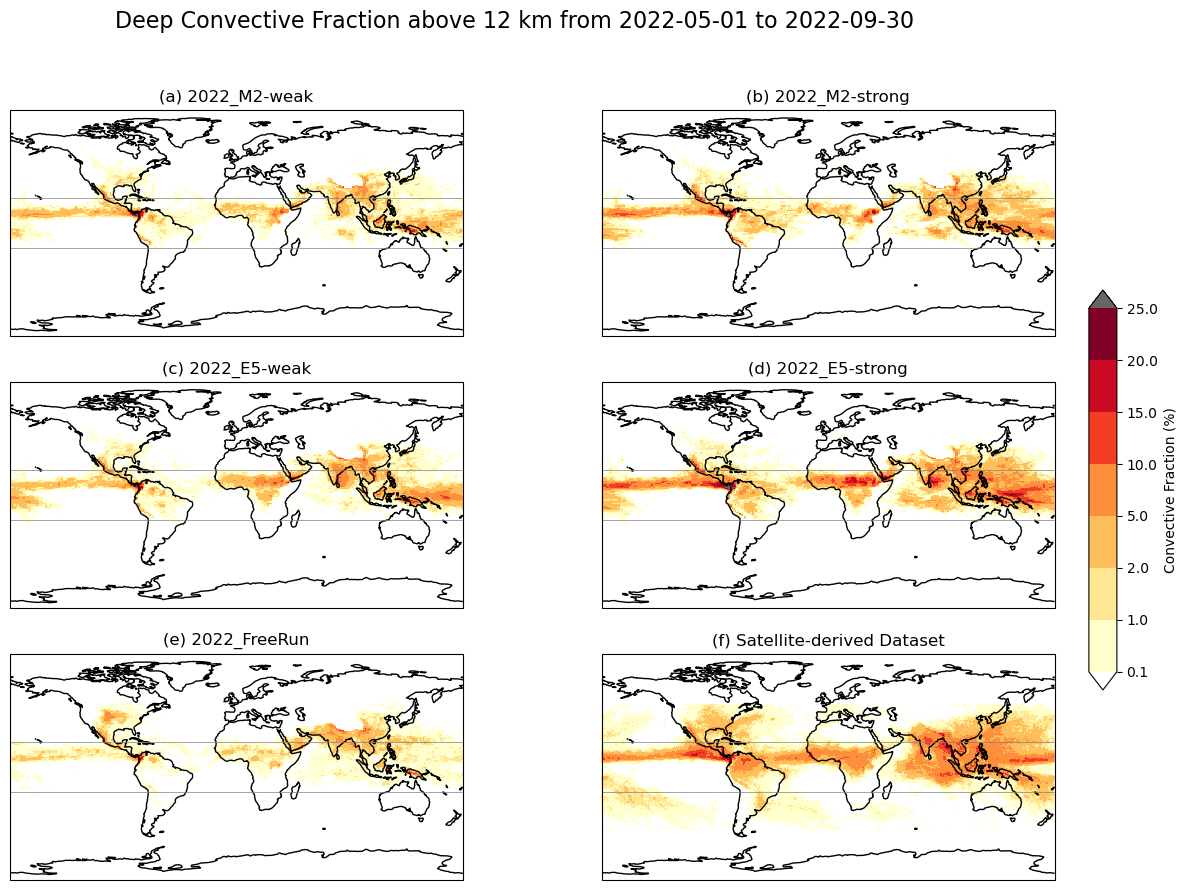

In [12]:

# Make a plot for the models
fig = plt.figure(figsize=(14,10))
ax0 = fig.add_subplot(3,2,1,projection=ccrs.PlateCarree())
ax1 = fig.add_subplot(3,2,2,projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(3,2,3,projection=ccrs.PlateCarree())
ax3 = fig.add_subplot(3,2,4,projection=ccrs.PlateCarree())
ax4 = fig.add_subplot(3,2,5,projection=ccrs.PlateCarree())
ax5 = fig.add_subplot(3,2,6,projection=ccrs.PlateCarree())

cmap = plt.get_cmap('YlOrRd')
cmap.set_under([1,1,1])
cmap.set_over([0.4,0.4,0.4])

#levels=[1,2,5,10,20,50]  # For global
levels = [0.1,1,2,5,10,15,20,25]  # For the ASM

norm = BoundaryNorm(levels, ncolors = cmap.N, clip = False)

convfrac_map_plot(ax0, simlon, simlat, sim0_convfrac, cmap, norm, sims[0], extent, '(a) ')
convfrac_map_plot(ax1, simlon, simlat, sim1_convfrac, cmap, norm, sims[1], extent, '(b) ')
convfrac_map_plot(ax2, simlon, simlat, sim2_convfrac, cmap, norm, sims[2], extent, '(c) ')
convfrac_map_plot(ax3, simlon, simlat, sim3_convfrac, cmap, norm, sims[3], extent, '(d) ')
convfrac_map_plot(ax4, simlon, simlat, sim4_convfrac, cmap, norm, sims[4], extent, '(e) ')

pixplt = ax5.pcolormesh(cloudlon, cloudlat, obsconvfrac, cmap=cmap, norm=norm)
ax5.coastlines()
ax5.set_title('(f) Satellite-derived Dataset')
ax5.set_extent(extent)
ax5.plot([-180,180],[20,20],linewidth=0.5,color='gray')
ax5.plot([-180,180],[-20,-20],linewidth=0.5,color='gray')

plt.suptitle('Deep Convective Fraction above ' + str(int(deep_thresh)) + ' km from ' + date0 + ' to ' + date1, fontsize=16)

cax = fig.add_axes([0.91,0.30,0.02,0.40])
cbar = plt.colorbar(pixplt, extend = 'both', orientation='vertical', cax=cax)
cbar.ax.set_ylabel('Convective Fraction (%)')

plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure1.png')
plt.savefig('/glade/u/home/wsmith/NudgeComparison_scripts/plots/Figure1.pdf')



# Make a plot for the models
fig = plt.figure(figsize=(14,8))
ax0 = fig.add_subplot(2,2,1,projection=ccrs.PlateCarree())
ax1 = fig.add_subplot(2,2,2,projection=ccrs.PlateCarree())
#ax2 = fig.add_subplot(2,2,(3,4),projection=ccrs.PlateCarree())
ax2 = fig.add_subplot(2,2,3,projection=ccrs.PlateCarree())
ax3 = fig.add_subplot(2,2,4,projection=ccrs.PlateCarree())

cmap = plt.get_cmap('YlOrRd')
cmap.set_under([1,1,1])
cmap.set_over([0.4,0.4,0.4])

#levels=[1,2,5,10,20,50]  # For global
levels = [0.1,1,2,5,10,15,20,25]  # For the ASM
norm = BoundaryNorm(levels, ncolors = cmap.N, clip = False)

pixplt = ax0.pcolormesh(simlon, simlat, sim0_convfrac, cmap=cmap, norm=norm)
pixplt = ax1.pcolormesh(simlon, simlat, sim2_convfrac, cmap=cmap, norm=norm)
pixplt = ax2.pcolormesh(cloudlon, cloudlat, obsconvfrac, cmap=cmap, norm=norm)
pixplt = ax3.pcolormesh(simlon, simlat, sim1_convfrac, cmap=cmap, norm=norm)

ax0.coastlines()
ax1.coastlines()
ax2.coastlines()
ax3.coastlines()

ax0.set_title('(a) ' + sims[0], fontsize=14)
ax1.set_title('(b) ' +  sims[2], fontsize=14)
ax2.set_title('(c) TRMM/CloudSat Observations', fontsize=14)
ax3.set_title('(d) ' + sims[1], fontsize=14)

ax0.set_extent(extent)
ax1.set_extent(extent)
ax2.set_extent(extent)
ax3.set_extent(extent)

#plt.suptitle('Deep Convective Fraction above ' + str(int(deep_thresh)) + ' hPa from ' + date0 + ' to ' + date1, fontsize=16)

cax = fig.add_axes([0.91,0.30,0.02,0.40])
cbar = plt.colorbar(pixplt, extend = 'both', orientation='vertical', cax=cax)
cbar.ax.set_ylabel('Convective Fraction (%)')



# Make a plot for the observations
fig = plt.figure(figsize=(16,10))
ax = fig.add_subplot(1,1,1,projection=ccrs.PlateCarree())

cmap = plt.get_cmap('YlOrRd')
cmap.set_under([1,1,1])
cmap.set_over([0.4,0.4,0.4])

#levels=[1,2,5,10,20,50]  # For global
levels = [0.1,1,2,5,10,15,20,25]  # For the ASM
norm = BoundaryNorm(levels, ncolors = cmap.N, clip = False)



ax.coastlines()

ax.set_title('Observed Deep Convective Fraction above ' + str(int(deep_thresh)) + ' hPa from ' + date0 + ' to ' + date1, fontsize=16)

ax.set_extent(extent)

#plt.suptitle(, fontsize=16)

#cax = fig.add_axes([0.91,0.30,0.02,0.40])
cbar = plt.colorbar(pixplt, extend = 'both', orientation='vertical')#, cax=cax)
cbar.ax.set_ylabel('Convective Fraction (%)')
